# Estudo de associação: quais variáveis não mentais se relacionam com a depressão?

## Objetivo

Testar, com estatística clássica (e não só com a importância do modelo), quais variáveis **de saúde física, funcionais, sociais e socioeconômicas** estão associadas à depressão (`SEVERIDADE_DEPRESSAO_PHQ`). Isso sustenta a hipótese do projeto: **é possível prever depressão sem usar sintomas de doenças mentais**.

## Por que não usar Pearson aqui

A base é quase toda formada por **códigos categóricos** (por exemplo, `ESTADO_CIVIL` = 1 a 9), e o valor `-1` significa *não respondeu*. O Pearson sobre os códigos trata o `-1` como se fosse um número real e assume que a diferença entre códigos é uma distância, o que só faz sentido para variáveis ordinais. Por isso:

1. O alvo é **binário** (`0` = sem depressão, nível 1 do PHQ; `1` = com depressão, níveis 2 a 4), como nos modelos.
2. O `-1` é tratado como **dado ausente** em cada variável (exclusão par a par), e não como categoria numérica.
3. A associação de cada variável com o alvo é medida pelo **V de Cramér** (com correção de viés), que funciona para variáveis nominais e ordinais. O **teste qui-quadrado** dá o p-valor.
4. Os p-valores são ajustados por **Benjamini-Hochberg (BH)**, por causa dos testes simultâneos.
5. Com ~23 mil registros, quase tudo sai "significativo". **A força da associação é o V de Cramér, não o p-valor.**
6. Como a idade pode confundir (idosos têm mais doenças físicas e perfis diferentes de depressão), repetimos a medida **dentro de faixas etárias**.

### Como ler o V de Cramér (alvo binário)

| V | Magnitude |
|---|---|
| < 0,10 | desprezível |
| 0,10 a 0,30 | pequena |
| 0,30 a 0,50 | média |
| ≥ 0,50 | grande |

As variáveis de **sintomas de depressão e ansiedade** ficam de fora: são exatamente o que queremos prever sem usar.

# 1. Carga dos dados e definição dos grupos de variáveis

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency, false_discovery_control, spearmanr

arquivo_csv = Path('01 Preparação dos dados') / 'dados' / 'limpos' / 'adult25_limpo.csv'
if not arquivo_csv.exists():
    arquivo_csv = Path('..') / arquivo_csv
if not arquivo_csv.exists():
    raise FileNotFoundError(f'Não foi possível encontrar o arquivo: {arquivo_csv.resolve()}')

dados = pd.read_csv(arquivo_csv)

ID_COLUNA = 'ID_DOMICILIO'
PESO = 'PESO_AMOSTRAL'
ALVO = 'SEVERIDADE_DEPRESSAO_PHQ'

# Sintomas de depressão (PHQ) e ansiedade (GAD-7): fora do estudo
COLUNAS_SINTOMAS = [
    'FREQ_PERDA_INTERESSE_2SEM', 'FREQ_SENTIU_DEPRIMIDO_2SEM',
    'FREQ_DIFICULDADE_DORMIR_2SEM', 'FREQ_CANSASO_2SEM',
    'FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM', 'FREQ_AUTOAVALIACAO_NEGTIVA_2SEM',
    'FREQ_DIFICULDADE_CONCENTRACAO_2SEM', 'MODIFICACAO_VELOCIDADE_FALA',
    'FREQ_DEPRESSAO', 'REMEDIO_DEPRESSAO', 'HISTORICO_DEPRESSAO',
    'INTENSIDADE_DEPRESSAO', 'SEVERIDADE_DEPRESSAO_PHQ',
    'HISTORICO_TRANSTORNO_ANSIEDADE', 'MED_ANSIEDADE',
    'FREQ_ANSIEDADE', 'INTENSIDADE_ANSIEDADE',
    'FREQ_ANSIEDADE_2SEM', 'FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM',
    'FREQ_PREOCUPACAO_DESNECESSARIA_2SEM', 'FREQ_DIFICULDADE_DESCANSAR_2SEM',
    'FREQ_AGITACAO_INQUIETA', 'FREQ_IRRITABILIDADE_2SEM',
    'FREQ_MEDO_2SEM', 'SEVERIDADE_ANSIEDADE'
]

# Variáveis estudadas, organizadas por tipo de informação
GRUPOS = {
    'Saúde física': [
        'CATEGORIA_IMC', 'HISTORICO_COLESTEROL', 'HISTORICO_DIABETES', 'HISTORICO_HIPERTENSAO',
        'HISTORICO_ARTRITE', 'ASMA_ATIVA_ATUALMENTE', 'TEVE_CANCER', 'DOR_CRONICA',
        'CONCUSSAO_SINTOMAS_POS_TRAUMA', 'JA_FUMANTE', 'AUTOAVALIACAO_SAUDE_GERAL'
    ],
    'Funcional e cognitiva': [
        'DIFICULDADE_LOCOMOCAO', 'LIMITACAO_TRABALHO_POR_SAUDE', 'DEFICIENTE',
        'FREQUENCIA_FALHA_MEMORIA', 'TIPO_DIFICULDADE_COGNITIVA', 'QTD_DIFICULDADE_COGNITIVA'
    ],
    'Vínculos e família': [
        'ESTADO_CIVIL_DECLARADO', 'ESTADO_CIVIL', 'STATUS_PARENTAL', 'SEXO_CONJUGE',
        'SEPARACAO_LEGAL_CONJUGAL', 'COJUGE_TRABALHA', 'FLG_IDOSO_FAMILIA',
        'QTD_ADULTOS_FAMILIA', 'QTD_CRIANÇAS_FAMILIA', 'SUPORTE_SOCIAL', 'FREQ_SOLITARIO'
    ],
    'Socioeconômica': [
        'ESCOLARIDADE_MAXIMA_FAMILIA', 'TEMPO_MORADIA_ANOS', 'TIPO_POSSE_IMOVEL',
        'CATEGORIA_RAZAO_POBREZA', 'RAZAO_RENDA_POBREZA', 'RENDA_INVESTIMENTOS',
        'ESTRESSE_FINANCEIRO_MEDICO'
    ],
    'Uso de serviços de saúde': [
        'ULTIMA_VISITA_MEDICO', 'VISITAS_PRONTO_ATENDIMENTO_12M', 'VISITAS_EMERGENCIA_HOSPITALAR_12M',
        'VISITAS_EXAME_VISTA_12M', 'PLANO_PUBLICO', 'PLANO_PRIVADO'
    ],
    'Demográfica': [
        'IDADE', 'SEXO', 'NATURAL_ESTADOS_UNIDOS', 'CLASSIFICACAO_URBANO_RURAL', 'REGIAO_GEOGRAFICA'
    ],
}

# Garante que nenhuma variável ficou de fora ou foi digitada errado
agrupadas = [c for colunas in GRUPOS.values() for c in colunas]
esperadas = set(dados.columns) - {ID_COLUNA, PESO} - set(COLUNAS_SINTOMAS)
assert len(agrupadas) == len(set(agrupadas)), 'Há variável repetida nos grupos'
assert set(agrupadas) == esperadas, f'Diferença: {set(agrupadas) ^ esperadas}'

# Alvo binário: remove não respondentes do PHQ (-1) e indefinidos (5)
dados = dados[~dados[ALVO].isin([-1, 5])].copy()
dados['DEPRESSAO'] = (dados[ALVO] != 1).astype(int)

# Faixas etárias usadas para ajustar pelo efeito da idade
dados['FAIXA_ETARIA'] = pd.cut(
    dados['IDADE'].replace(-1, np.nan), [17, 34, 49, 64, 120], labels=['18-34', '35-49', '50-64', '65+']
)

print(f'Registros com alvo definido: {len(dados)}')
print(f'Variáveis estudadas: {len(agrupadas)} em {len(GRUPOS)} grupos')
print(f"Prevalência de depressão: {dados['DEPRESSAO'].mean():.1%} (simples) | "
      f"{np.average(dados['DEPRESSAO'], weights=dados[PESO]):.1%} (ponderada pelo peso amostral)")

Registros com alvo definido: 23619
Variáveis estudadas: 46 em 6 grupos
Prevalência de depressão: 21.2% (simples) | 21.4% (ponderada pelo peso amostral)


# 2. Funções de apoio

- `discretizar`: troca `-1` por ausente e agrupa as duas variáveis contínuas (`IDADE` em faixas e `RAZAO_RENDA_POBREZA` em quintis), para que todas possam ser medidas com a mesma métrica e comparadas entre si.
- `cramers_v`: V de Cramér com correção de viés (Bergsma), junto com o qui-quadrado e o p-valor.
- `prevalencia_por_nivel`: percentual de depressão em cada nível da variável, **ponderado pelo peso amostral**, que mostra a *direção* da associação.
- `v_dentro_da_idade`: média do V de Cramér calculado dentro de cada faixa etária (ponderada pelo tamanho da faixa). Se a associação se mantém, ela não é só efeito da idade.

In [2]:
def discretizar(coluna):
    serie = dados[coluna].replace(-1, np.nan)
    if coluna == 'IDADE':
        return pd.cut(serie, [17, 29, 39, 49, 59, 69, 120])
    if coluna == 'RAZAO_RENDA_POBREZA':
        return pd.qcut(serie, 5, duplicates='drop')
    return serie


def cramers_v(tabela):
    chi2, p_valor, _, _ = chi2_contingency(tabela, correction=False)
    n = tabela.to_numpy().sum()
    linhas, colunas = tabela.shape
    phi2 = max(0.0, chi2 / n - (colunas - 1) * (linhas - 1) / (n - 1))
    linhas_corr = linhas - (linhas - 1) ** 2 / (n - 1)
    colunas_corr = colunas - (colunas - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(colunas_corr - 1, linhas_corr - 1)), chi2, p_valor


def prevalencia_por_nivel(serie, minimo=50):
    base = pd.DataFrame({'nivel': serie, 'y': dados['DEPRESSAO'], 'w': dados[PESO]}).dropna(subset=['nivel'])
    base['yw'] = base['y'] * base['w']
    por_nivel = base.groupby('nivel', observed=True).agg(n=('y', 'size'), soma_yw=('yw', 'sum'), soma_w=('w', 'sum'))
    por_nivel['prevalencia'] = por_nivel['soma_yw'] / por_nivel['soma_w']
    return por_nivel[por_nivel['n'] >= minimo][['n', 'prevalencia']]


def v_dentro_da_idade(serie):
    valores, pesos = [], []
    for faixa, indices in dados.groupby('FAIXA_ETARIA', observed=True).groups.items():
        tabela = pd.crosstab(serie.loc[indices], dados.loc[indices, 'DEPRESSAO'])
        if tabela.shape[0] < 2 or tabela.shape[1] < 2:
            continue
        valores.append(cramers_v(tabela)[0])
        pesos.append(tabela.to_numpy().sum())
    return np.average(valores, weights=pesos) if valores else np.nan


def magnitude(v):
    return ['desprezível', 'pequena', 'média', 'grande'][int((v >= np.array([0.1, 0.3, 0.5])).sum())]


def formatar(tabela, formatos):
    # Formata colunas para exibição sem depender do jinja2 (necessário para DataFrame.style)
    tabela = tabela.copy()
    for coluna, formato in formatos.items():
        tabela[coluna] = tabela[coluna].map(lambda x, f=formato: f.format(x))
    return tabela

# 3. Associação de cada variável com a depressão

Colunas da tabela:

- `V_Cramer`: força da associação (0 = nenhuma; quanto maior, mais forte).
- `V_dentro_da_idade`: o mesmo, calculado dentro das faixas etárias. Se cair muito em relação a `V_Cramer`, parte da associação era efeito da idade.
- `prev_min` / `prev_max`: menor e maior percentual de depressão (ponderado) entre os níveis da variável, considerando níveis com pelo menos 50 registros.
- `razao_prev`: `prev_max / prev_min`, ou seja, quantas vezes a depressão é mais frequente no nível de maior risco.

In [3]:
linhas = []
for grupo, colunas in GRUPOS.items():
    for coluna in colunas:
        serie = discretizar(coluna)
        tabela = pd.crosstab(serie, dados['DEPRESSAO'])
        if tabela.shape[0] < 2:
            continue
        v, chi2, p_valor = cramers_v(tabela)
        prevalencias = prevalencia_por_nivel(serie)['prevalencia']
        linhas.append({
            'coluna': coluna,
            'grupo': grupo,
            'n': int(tabela.to_numpy().sum()),
            'V_Cramer': v,
            'magnitude': magnitude(v),
            'V_dentro_da_idade': np.nan if coluna == 'IDADE' else v_dentro_da_idade(serie),
            'prev_min': prevalencias.min(),
            'prev_max': prevalencias.max(),
            'razao_prev': prevalencias.max() / prevalencias.min() if prevalencias.min() > 0 else np.nan,
            'chi2': chi2,
            'p_valor': p_valor,
        })

ranking = pd.DataFrame(linhas)
ranking['p_ajustado_BH'] = false_discovery_control(ranking['p_valor'].to_numpy(), method='bh')
ranking['significativo_BH_5%'] = ranking['p_ajustado_BH'] < 0.05
ranking = ranking.sort_values('V_Cramer', ascending=False).reset_index(drop=True)

print(f"{ranking['significativo_BH_5%'].sum()} de {len(ranking)} variáveis significativas após ajuste BH (5%)")
print('Magnitude da associação:', ranking['magnitude'].value_counts().to_dict(), '\n')
colunas_exibir = ['coluna', 'grupo', 'V_Cramer', 'magnitude', 'V_dentro_da_idade', 'prev_min', 'prev_max', 'razao_prev', 'p_ajustado_BH']
display(formatar(ranking[colunas_exibir], {
    'V_Cramer': '{:.3f}', 'V_dentro_da_idade': '{:.3f}', 'prev_min': '{:.1%}', 'prev_max': '{:.1%}',
    'razao_prev': '{:.1f}', 'p_ajustado_BH': '{:.2e}'
}))

44 de 46 variáveis significativas após ajuste BH (5%)
Magnitude da associação: {'desprezível': 24, 'pequena': 16, 'média': 6} 



,coluna,grupo,V_Cramer,magnitude,V_dentro_da_idade,prev_min,prev_max,razao_prev,p_ajustado_BH
0,FREQ_SOLITARIO,Vínculos e família,0.398,média,0.394,8.7%,69.2%,7.9,0.00e+00
1,TIPO_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.395,média,0.398,12.4%,59.2%,4.8,0.00e+00
2,QTD_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.385,média,0.395,12.4%,80.6%,6.5,0.00e+00
3,FREQUENCIA_FALHA_MEMORIA,Funcional e cognitiva,0.347,média,0.361,14.4%,68.8%,4.8,0.00e+00
4,AUTOAVALIACAO_SAUDE_GERAL,Saúde física,0.317,média,0.345,9.1%,62.6%,6.9,0.00e+00
5,DOR_CRONICA,Saúde física,0.305,média,0.334,10.5%,47.5%,4.5,0.00e+00
6,SUPORTE_SOCIAL,Vínculos e família,0.275,pequena,0.274,13.0%,52.7%,4.0,0.00e+00
7,LIMITACAO_TRABALHO_POR_SAUDE,Funcional e cognitiva,0.271,pequena,0.294,16.3%,43.9%,2.7,0.00e+00
8,DEFICIENTE,Funcional e cognitiva,0.266,pequena,0.288,17.9%,54.1%,3.0,0.00e+00
9,DIFICULDADE_LOCOMOCAO,Funcional e cognitiva,0.235,pequena,0.281,17.4%,54.6%,3.1,2.33e-282


# 4. Resumo por grupo e gráfico

O resumo mostra qual **tipo de informação** carrega mais associação com a depressão: saúde física, funcionalidade, vínculos sociais, condição socioeconômica, uso de serviços ou dados demográficos.

,variaveis,V_medio,V_maximo,com_associacao_pequena_ou_maior
grupo,,,,
Funcional e cognitiva,6,0.316,0.395,6
Saúde física,11,0.124,0.317,5
Socioeconômica,7,0.123,0.196,4
Vínculos e família,11,0.121,0.398,5
Uso de serviços de saúde,6,0.072,0.176,2
Demográfica,5,0.052,0.078,0


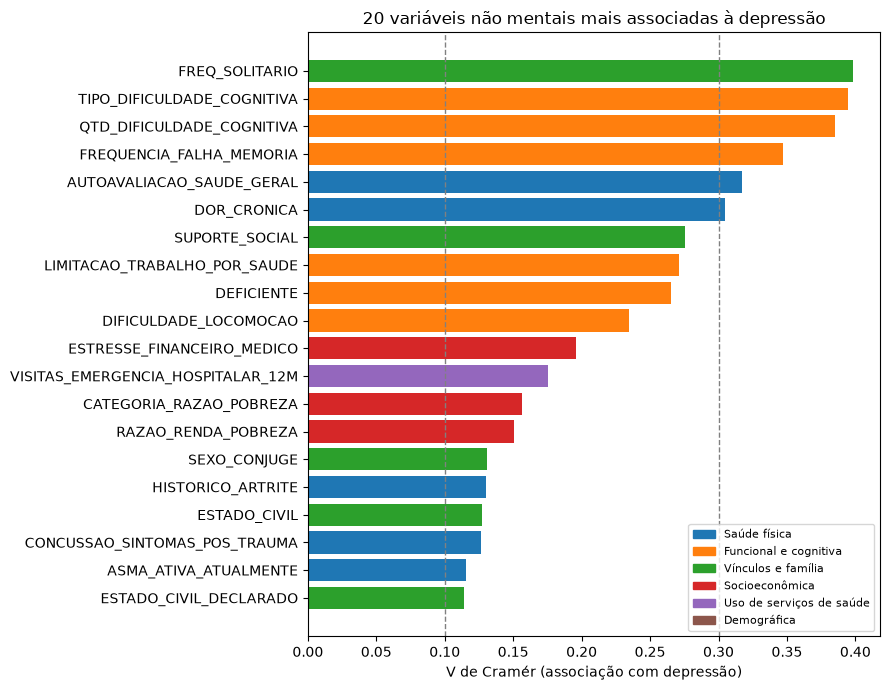

In [4]:
resumo = ranking.groupby('grupo').agg(
    variaveis=('coluna', 'size'),
    V_medio=('V_Cramer', 'mean'),
    V_maximo=('V_Cramer', 'max'),
    com_associacao_pequena_ou_maior=('V_Cramer', lambda s: int((s >= 0.1).sum())),
).sort_values('V_medio', ascending=False)
display(formatar(resumo, {'V_medio': '{:.3f}', 'V_maximo': '{:.3f}'}))

top = ranking.head(20).iloc[::-1]
cores = dict(zip(GRUPOS, plt.cm.tab10.colors))
plt.figure(figsize=(9, 7))
plt.barh(top['coluna'], top['V_Cramer'], color=[cores[g] for g in top['grupo']])
plt.axvline(0.1, color='gray', linestyle='--', linewidth=1)
plt.axvline(0.3, color='gray', linestyle='--', linewidth=1)
plt.xlabel('V de Cramér (associação com depressão)')
plt.title('20 variáveis não mentais mais associadas à depressão')
plt.legend(handles=[Patch(color=cor, label=g) for g, cor in cores.items()], loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

# 5. Saúde física e funcionalidade: a hipótese das doenças físicas

Aqui isolamos os dois grupos que representam a parte "física" da hipótese. A coluna `V_dentro_da_idade` indica quais associações **resistem ao controle pela idade**.

In [5]:
fisicas = ranking[ranking['grupo'].isin(['Saúde física', 'Funcional e cognitiva'])]
display(formatar(fisicas[['coluna', 'grupo', 'V_Cramer', 'magnitude', 'V_dentro_da_idade', 'prev_min', 'prev_max', 'razao_prev']], {
    'V_Cramer': '{:.3f}', 'V_dentro_da_idade': '{:.3f}', 'prev_min': '{:.1%}', 'prev_max': '{:.1%}', 'razao_prev': '{:.1f}'
}))

,coluna,grupo,V_Cramer,magnitude,V_dentro_da_idade,prev_min,prev_max,razao_prev
1,TIPO_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.395,média,0.398,12.4%,59.2%,4.8
2,QTD_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.385,média,0.395,12.4%,80.6%,6.5
3,FREQUENCIA_FALHA_MEMORIA,Funcional e cognitiva,0.347,média,0.361,14.4%,68.8%,4.8
4,AUTOAVALIACAO_SAUDE_GERAL,Saúde física,0.317,média,0.345,9.1%,62.6%,6.9
5,DOR_CRONICA,Saúde física,0.305,média,0.334,10.5%,47.5%,4.5
7,LIMITACAO_TRABALHO_POR_SAUDE,Funcional e cognitiva,0.271,pequena,0.294,16.3%,43.9%,2.7
8,DEFICIENTE,Funcional e cognitiva,0.266,pequena,0.288,17.9%,54.1%,3.0
9,DIFICULDADE_LOCOMOCAO,Funcional e cognitiva,0.235,pequena,0.281,17.4%,54.6%,3.1
15,HISTORICO_ARTRITE,Saúde física,0.130,pequena,0.177,18.8%,31.3%,1.7
17,CONCUSSAO_SINTOMAS_POS_TRAUMA,Saúde física,0.127,pequena,0.127,20.6%,54.4%,2.6


# 6. Estudo de caso: `DOR_CRONICA`

Detalhamos uma variável de saúde física para mostrar a *direção* da relação: percentual de depressão em cada nível, e se o padrão se repete em todas as faixas etárias. Os códigos `1` a `4` são tratados como ordem crescente (a depressão aumenta junto com o código, o que sugere uma escala de frequência ou intensidade; **confirme o significado dos códigos no dicionário de variáveis**). O `-1` fica de fora.

In [6]:
VARIAVEL_CASO = 'DOR_CRONICA'
serie = discretizar(VARIAVEL_CASO)

# Prevalência ponderada por nível
por_nivel = prevalencia_por_nivel(serie)
por_nivel['prevalencia'] = por_nivel['prevalencia'].map('{:.1%}'.format)
print(f'Prevalência de depressão por nível de {VARIAVEL_CASO} (ponderada):')
display(por_nivel)

# Tendência monotônica (assume ordem dos códigos)
mascara = serie.notna()
rho, p_rho = spearmanr(serie[mascara], dados.loc[mascara, 'DEPRESSAO'])
print(f'Spearman (tendência com o nível): rho = {rho:.3f} | p = {p_rho:.2e}\n')

# O padrão se mantém dentro de cada faixa etária?
base = pd.DataFrame({
    'nivel': serie, 'faixa': dados['FAIXA_ETARIA'], 'y': dados['DEPRESSAO'], 'w': dados[PESO]
}).dropna()
base['yw'] = base['y'] * base['w']
soma = base.groupby(['faixa', 'nivel'], observed=True)[['yw', 'w']].sum()
por_faixa = (soma['yw'] / soma['w']).unstack('nivel')
print('Prevalência ponderada de depressão por faixa etária e nível:')
display(por_faixa.map('{:.1%}'.format))

Prevalência de depressão por nível de DOR_CRONICA (ponderada):


,n,prevalencia
nivel,,
1.0,8366,10.5%
2.0,9601,20.1%
3.0,2152,39.2%
4.0,3433,47.5%


Spearman (tendência com o nível): rho = 0.288 | p = 0.00e+00

Prevalência ponderada de depressão por faixa etária e nível:


nivel,1.0,2.0,3.0,4.0
faixa,,,,
18-34,15.9%,30.6%,55.2%,62.4%
35-49,8.8%,21.4%,45.5%,55.2%
50-64,6.0%,13.9%,34.5%,48.7%
65+,6.5%,12.6%,26.4%,38.7%


# 7. Principais resultados

Execução com 23.619 registros (prevalência de depressão de 21,2%). **44 das 46 variáveis são significativas após o ajuste BH**, mas só **6 têm associação média** (V de 0,30 a 0,40) e 16 têm associação pequena. As outras 24 são desprezíveis, mesmo quando o p-valor é minúsculo.

**1. O que mais se associa à depressão sem usar sintomas mentais**

| Variável | Grupo | V de Cramér | Depressão: menor → maior nível |
|---|---|---|---|
| `FREQ_SOLITARIO` | Vínculos | 0,40 | 8,7% → 69,2% |
| `TIPO_DIFICULDADE_COGNITIVA` | Funcional | 0,40 | 12,4% → 59,2% |
| `QTD_DIFICULDADE_COGNITIVA` | Funcional | 0,39 | 12,4% → 80,6% |
| `FREQUENCIA_FALHA_MEMORIA` | Funcional | 0,35 | 14,4% → 68,8% |
| `AUTOAVALIACAO_SAUDE_GERAL` | Saúde física | 0,32 | 9,1% → 62,6% |
| `DOR_CRONICA` | Saúde física | 0,31 | 10,5% → 47,5% |

**2. Dor crônica responde à pergunta original.** A associação é média (V = 0,31) e sobe a cada nível: 10,5%, 20,1%, 39,2% e 47,5% de depressão. O padrão se repete **em todas as faixas etárias** (por exemplo, de 15,9% a 62,4% entre 18 e 34 anos e de 6,5% a 38,7% a partir dos 65). Logo, não é efeito da idade. O V dentro das faixas (0,33) é até maior que o geral (0,31).

**3. Importante para a hipótese: as doenças crônicas clássicas pesam pouco.** Diabetes (V = 0,07), hipertensão (0,05), colesterol (0,05) e câncer (0,02) têm associação **desprezível** com depressão. Artrite, asma e sequelas de trauma ficam na faixa pequena (V entre 0,12 e 0,13). O sinal físico vem de **como a pessoa se sente e funciona** (dor, autoavaliação de saúde, limitações, mobilidade, cognição), e não do diagnóstico de uma doença específica. Hipertensão, colesterol e diabetes ganham algum peso dentro das faixas etárias (V de cerca de 0,08 a 0,09 contra 0,05 a 0,07 no geral), pois a idade mascara parte da relação: idosos têm mais dessas doenças, mas menos depressão.

**4. Por grupo** (V médio): funcional e cognitiva (0,32), saúde física (0,12), socioeconômica (0,12), vínculos e família (0,12), uso de serviços (0,07) e demográfica (0,05). Idade, sexo e região, sozinhos, explicam pouco.

**5. Consistência com o modelo.** As variáveis mais associadas aqui são as mesmas que lideram o Random Forest sem ansiedade (`06_03_comparativo_com_sem_ansiedade_2025.ipynb`): solidão, dificuldade cognitiva, suporte social, autoavaliação de saúde e dor crônica. Duas leituras independentes apontando para as mesmas variáveis fortalecem a conclusão.

**Ressalva para a defesa da hipótese.** `FREQ_SOLITARIO`, `FREQUENCIA_FALHA_MEMORIA` e as dificuldades cognitivas podem **se sobrepor a sintomas depressivos** (isolamento e dificuldade de concentração fazem parte do quadro), e não ser apenas fatores de risco independentes. Já dor crônica, limitações físicas e mobilidade são menos suscetíveis a esse problema. Para a tese de "prever depressão com dados físicos", vale destacar esse segundo grupo.

# 8. Como interpretar e limitações

- **Significância não é importância.** Com milhares de registros, até associações minúsculas têm p-valor ≈ 0. Por isso a leitura se apoia no V de Cramér e na razão de prevalências.
- **Associação não é causa.** Dor crônica pode aumentar o risco de depressão, a depressão pode aumentar a percepção de dor, e fatores comuns (renda, idade, isolamento) podem explicar os dois.
- **Ajuste só por idade.** `V_dentro_da_idade` controla apenas a idade. Outras variáveis também podem confundir.
- **Desenho amostral.** O qui-quadrado usa as contagens brutas, sem corrigir o desenho complexo da pesquisa (estratos e conglomerados). Os p-valores tendem a ser otimistas, mas o V de Cramér e as prevalências ponderadas continuam servindo para ordenar as variáveis.
- **Ausentes.** Cada variável é analisada sem os respondentes com `-1`; o `n` varia um pouco entre variáveis (a maioria perde menos de 4%).
- **Relação com os modelos.** A importância das variáveis no Random Forest (`06_03_comparativo_com_sem_ansiedade_2025.ipynb`) mede utilidade para *prever*, enquanto este estudo mede *associação*. Quando as duas leituras apontam para as mesmas variáveis, a evidência é mais forte.